FileNotFoundError: [Errno 2] No such file or directory: '../dataset/samples/contoh_gangguan.png'

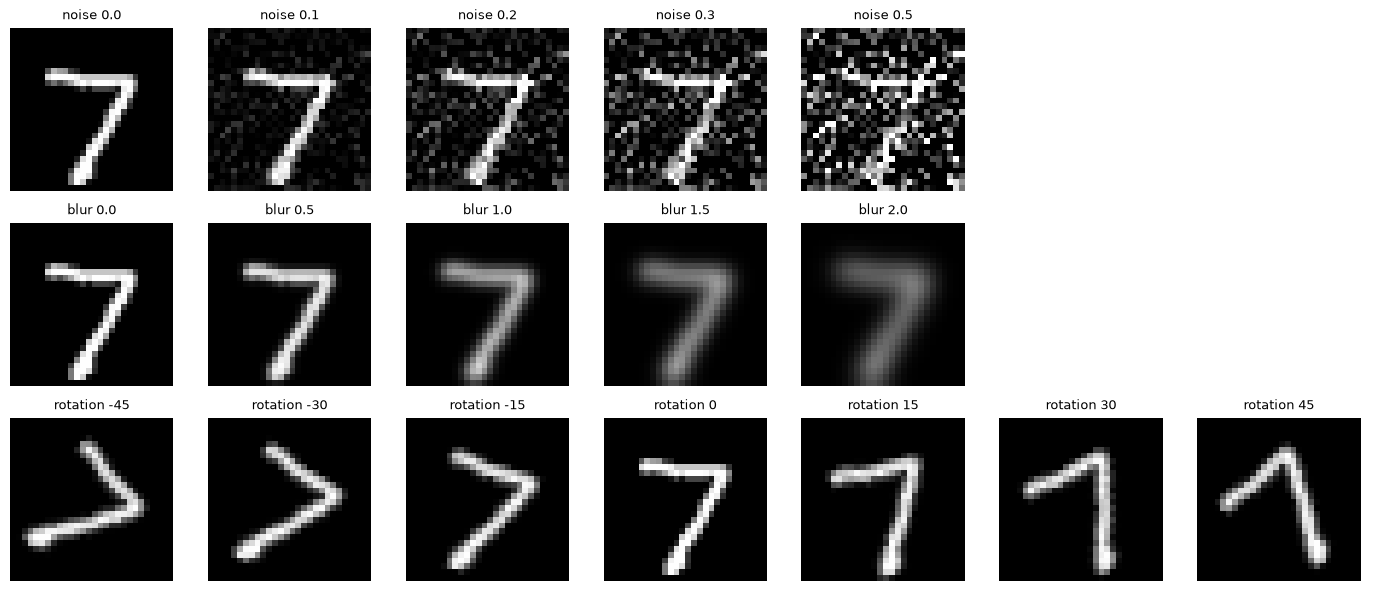

In [1]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

D = Path('..') / 'dataset' / 'perturbed'
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for row, name in enumerate(['noise', 'blur', 'rotation']):
    d = np.load(D / f'{name}.npz')
    for col in range(7):
        ax = axes[row, col]; ax.axis('off')
        if col < len(d['levels']):
            ax.imshow(d['X'][col, 0, :, :, 0], cmap='gray', vmin=0, vmax=255)
            ax.set_title(f"{name} {d['levels'][col]}", fontsize=9)
plt.tight_layout()
plt.savefig('../dataset/samples/contoh_gangguan.png', dpi=150)
plt.show()

In [1]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

D = Path('../dataset/perturbed'); FIG = Path('../report/figures')
model = tf.keras.models.load_model('model_cnn_mnist.keras')

In [2]:
results = {}
for name in ['noise', 'blur', 'rotation']:
    d = np.load(D / f'{name}.npz')
    y = to_categorical(d['y'], 10)
    accs = []
    for i, lv in enumerate(d['levels']):
        X = d['X'][i].astype('float32') / 255.0      # penting: bagi 255
        accs.append(model.evaluate(X, y, verbose=0)[1])
    results[name] = (d['levels'], np.array(accs))
    print(name)
    for lv, a in zip(d['levels'], accs): print(f'  level {lv}: {a:.4f}')

noise
  level 0.0: 0.9874
  level 0.1: 0.9849
  level 0.2: 0.9781
  level 0.3: 0.9436
  level 0.5: 0.6287
blur
  level 0.0: 0.9874
  level 0.5: 0.9868
  level 1.0: 0.9830
  level 1.5: 0.9667
  level 2.0: 0.9226
rotation
  level -45: 0.4635
  level -30: 0.7795
  level -15: 0.9589
  level 0: 0.9874
  level 15: 0.9667
  level 30: 0.8299
  level 45: 0.5480


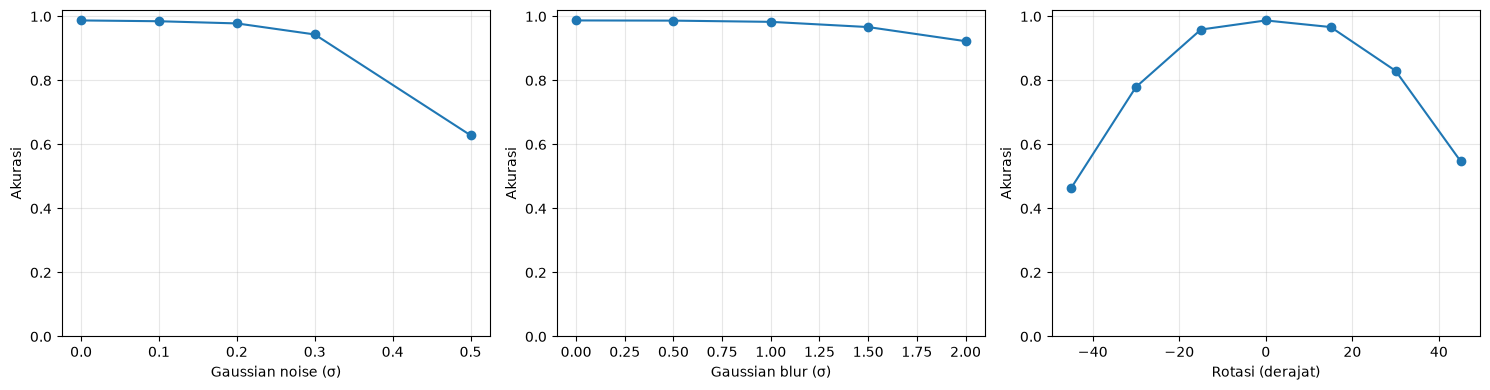

In [3]:
titles = {'noise':'Gaussian noise (σ)', 'blur':'Gaussian blur (σ)', 'rotation':'Rotasi (derajat)'}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax, results):
    lv, acc = results[name]
    a.plot(lv, acc, 'o-'); a.set_xlabel(titles[name]); a.set_ylabel('Akurasi')
    a.set_ylim(0, 1.02); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'akurasi_vs_gangguan.png', dpi=150); plt.show()

In [4]:
for name, (lv, acc) in results.items():
    print(f'| {name} | ' + ' | '.join(f'{l}' for l in lv) + ' |')
    print('| Akurasi | ' + ' | '.join(f'{a*100:.2f}%' for a in acc) + ' |\n')

| noise | 0.0 | 0.1 | 0.2 | 0.3 | 0.5 |
| Akurasi | 98.74% | 98.49% | 97.81% | 94.36% | 62.87% |

| blur | 0.0 | 0.5 | 1.0 | 1.5 | 2.0 |
| Akurasi | 98.74% | 98.68% | 98.30% | 96.67% | 92.26% |

| rotation | -45 | -30 | -15 | 0 | 15 | 30 | 45 |
| Akurasi | 46.35% | 77.95% | 95.89% | 98.74% | 96.67% | 82.99% | 54.80% |



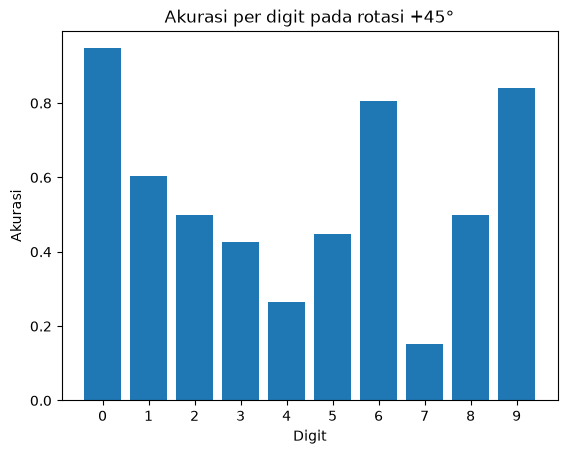

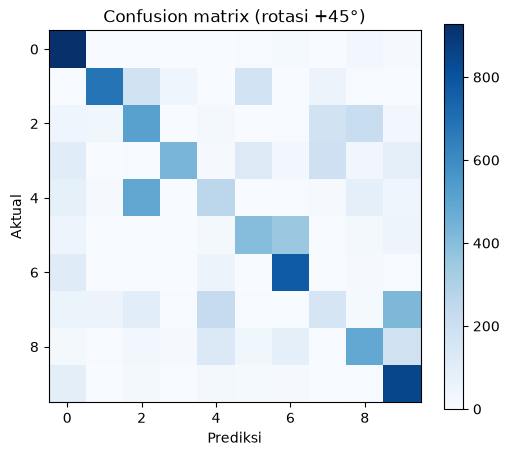

In [5]:
d = np.load(D / 'rotation.npz'); X = d['X'][-1].astype('float32')/255.0   # rotasi +45°
pred = np.argmax(model.predict(X, verbose=0), axis=1); true = d['y']
per_digit = [(pred[true==k]==k).mean() for k in range(10)]
plt.bar(range(10), per_digit); plt.xticks(range(10)); plt.xlabel('Digit'); plt.ylabel('Akurasi')
plt.title('Akurasi per digit pada rotasi +45°')
plt.savefig(FIG/'akurasi_per_digit_rot45.png', dpi=150); plt.show()

cm = confusion_matrix(true, pred)
plt.figure(figsize=(6,5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion matrix (rotasi +45°)')
plt.savefig(FIG/'confusion_rot45.png', dpi=150); plt.show()

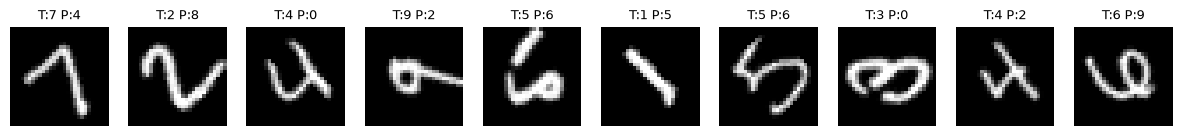

In [6]:
wrong = np.where(pred != true)[0][:10]
fig, ax = plt.subplots(1, 10, figsize=(15, 2))
for a, i in zip(ax, wrong):
    a.imshow(X[i,...,0], cmap='gray'); a.set_title(f'T:{true[i]} P:{pred[i]}', fontsize=9); a.axis('off')
plt.savefig(FIG/'contoh_salah_rot45.png', dpi=150, bbox_inches='tight'); plt.show()

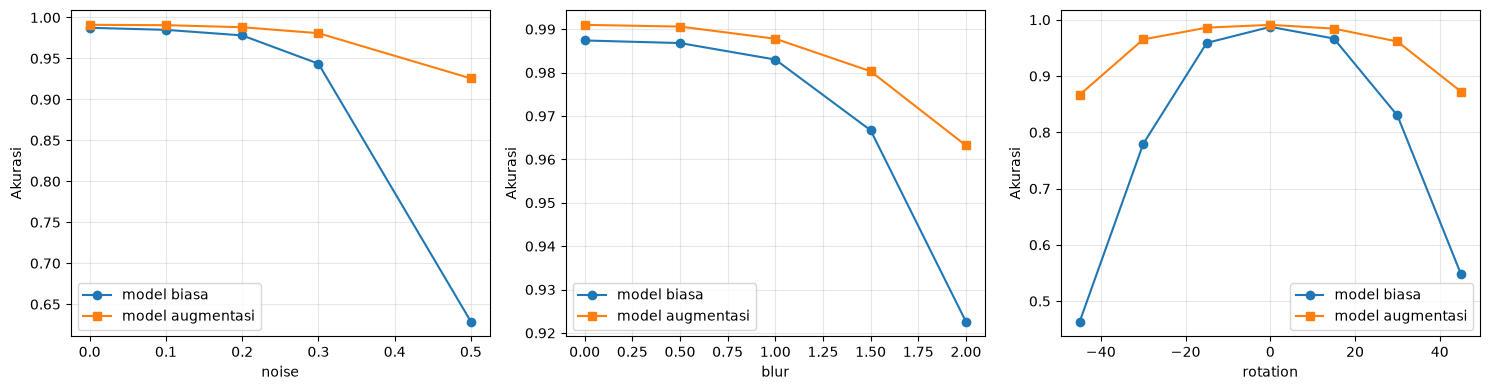

In [7]:
model_aug = tf.keras.models.load_model('model_cnn_augmented.keras')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax, ['noise', 'blur', 'rotation']):
    d = np.load(D / f'{name}.npz'); y = to_categorical(d['y'], 10)
    acc_b, acc_a = [], []
    for i in range(len(d['levels'])):
        X = d['X'][i].astype('float32') / 255.0
        acc_b.append(model.evaluate(X, y, verbose=0)[1])
        acc_a.append(model_aug.evaluate(X, y, verbose=0)[1])
    a.plot(d['levels'], acc_b, 'o-', label='model biasa')
    a.plot(d['levels'], acc_a, 's-', label='model augmentasi')
    a.set_xlabel(name); a.set_ylabel('Akurasi'); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'perbandingan_biasa_vs_augmentasi.png', dpi=150); plt.show()

In [1]:
import numpy as np, tensorflow as tf
from pathlib import Path
from tensorflow.keras.utils import to_categorical

D = Path('../dataset/perturbed')
model     = tf.keras.models.load_model('model_cnn_mnist.keras')
model_aug = tf.keras.models.load_model('model_cnn_augmented.keras')

fmt = lambda a: f'{a*100:.2f}%'.replace('.', ',')

# ---- 5.1 Data bersih (10.000 citra test asli) ----
(_, _), (Xt, yt) = tf.keras.datasets.mnist.load_data()
Xt = (Xt.astype('float32') / 255.0)[..., None]; Yt = to_categorical(yt, 10)
print('### 5.1')
for nama, m in [('Baseline', model), ('Beraugmentasi', model_aug)]:
    loss, acc = m.evaluate(Xt, Yt, verbose=0)
    print(f'| **{nama}** | **{fmt(acc)}** | {loss:.4f} |')

# ---- 5.2 - 5.4 Tabel per gangguan ----
hasil = {}
for bagian, name in [('5.2', 'noise'), ('5.3', 'blur'), ('5.4', 'rotation')]:
    d = np.load(D / f'{name}.npz'); Y = to_categorical(d['y'], 10)
    ab, aa = [], []
    for i in range(len(d['levels'])):
        X = d['X'][i].astype('float32') / 255.0
        ab.append(model.evaluate(X, Y, verbose=0)[1])
        aa.append(model_aug.evaluate(X, Y, verbose=0)[1])
    hasil[name] = (d['levels'], np.array(ab), np.array(aa))
    print(f'\n### {bagian} {name}')
    print('| level | ' + ' | '.join(str(l) for l in d['levels']) + ' |')
    print('| **Baseline** | ' + ' | '.join(fmt(a) for a in ab) + ' |')
    print('| **Beraugmentasi** | ' + ' | '.join(fmt(a) for a in aa) + ' |')

### 5.1
| **Baseline** | **98,74%** | 0.0431 |
| **Beraugmentasi** | **99,10%** | 0.0451 |

### 5.2 noise
| level | 0.0 | 0.1 | 0.2 | 0.3 | 0.5 |
| **Baseline** | 98,74% | 98,49% | 97,81% | 94,36% | 62,87% |
| **Beraugmentasi** | 99,10% | 99,06% | 98,81% | 98,08% | 92,56% |

### 5.3 blur
| level | 0.0 | 0.5 | 1.0 | 1.5 | 2.0 |
| **Baseline** | 98,74% | 98,68% | 98,30% | 96,67% | 92,26% |
| **Beraugmentasi** | 99,10% | 99,06% | 98,78% | 98,03% | 96,32% |

### 5.4 rotation
| level | -45 | -30 | -15 | 0 | 15 | 30 | 45 |
| **Baseline** | 46,35% | 77,95% | 95,89% | 98,74% | 96,67% | 82,99% | 54,80% |
| **Beraugmentasi** | 86,67% | 96,51% | 98,60% | 99,10% | 98,43% | 96,14% | 87,25% |


In [2]:
print('Penurunan akurasi pada level terberat (baseline -> augmentasi):')
for name, (lv, ab, aa) in hasil.items():
    print(f'{name:9s} level {lv[-1]}: baseline {fmt(ab[0])}->{fmt(ab[-1])} '
          f'| augmentasi {fmt(aa[0])}->{fmt(aa[-1])}')

# Akurasi per digit pada rotasi +45 derajat (indeks terakhir)
d = np.load(D / 'rotation.npz'); X = d['X'][-1].astype('float32') / 255.0
for nama, m in [('baseline', model), ('augmentasi', model_aug)]:
    p = np.argmax(m.predict(X, verbose=0), axis=1)
    per = [(p[d['y']==k] == k).mean() for k in range(10)]
    print(f'\n{nama}, rotasi +45 derajat:')
    print('  ' + ' '.join(f'{k}:{fmt(v)}' for k, v in enumerate(per)))
    print('  digit paling rentan:', int(np.argmin(per)))

Penurunan akurasi pada level terberat (baseline -> augmentasi):
noise     level 0.5: baseline 98,74%->62,87% | augmentasi 99,10%->92,56%
blur      level 2.0: baseline 98,74%->92,26% | augmentasi 99,10%->96,32%
rotation  level 45: baseline 46,35%->54,80% | augmentasi 86,67%->87,25%

baseline, rotasi +45 derajat:
  0:94,69% 1:60,26% 2:50,00% 3:42,77% 4:26,48% 5:44,73% 6:80,58% 7:15,08% 8:50,00% 9:83,94%
  digit paling rentan: 7

augmentasi, rotasi +45 derajat:
  0:98,78% 1:97,36% 2:81,69% 3:90,30% 4:75,36% 5:88,12% 6:87,79% 7:83,46% 8:73,61% 9:94,65%
  digit paling rentan: 8
